## Caso 0 (paper) sui dataset completi

Notebook ricavato dalla sezione **V1** del notebook di Marco (`notebook_marco.ipynb`): dati, k-fold, early stopping, baseline sul volume e metriche sono **invariati**.
Cambia **solo il modello**, che diventa il caso 0 del paper (Stodt et al., Sez. 4.2.2 e 4.4):

- feature dei nodi: community label, in-degree, out-degree (già così nella V1);
- **funzione di valutazione degli archi Φ** (eq. 4): per ogni tipo di arco `Φ = Σ αᵢ · Norm(xᵢ)`, con αᵢ appresi e passati alle `GCNConv` come `edge_weight`.

Mie scelte dove il paper non specifica (come nel caso 0 sul venerdì): `log1p` e poi **min-max calcolato solo sul train di ogni fold**; **α ≥ 0** tramite softplus, inizializzati a 0.5.

Prima esecuzione: lasciare `PROVA_RAPIDA = True` (solo CIC-IDS2017, fold 1, 5 epoche) per verificare che tutto funzioni e misurare i tempi.


In [11]:
!pip install torch_geometric

In [ ]:
# V1 / 1. CONFIGURAZIONE E DATI COMPLETI

# Setup: Python 3.12; da questa cartella: python -m pip install -r requirements.txt (credo sia sufficiente anche in un virtualenv); poi apri questo notebook in JupyterLab o dove preferisci.
# Seleziona quel kernel ed esegui le quattro celle della sola V1 oppure V2.

# Gli output salvati sono storici: riesegui le celle per valutare la configurazione attuale.

from pathlib import Path
from datetime import datetime
import os

# Kaggle: attivare Internet e GPU nelle impostazioni del notebook; se manca: !pip install torch_geometric
PROVA_RAPIDA = False  # True = solo CIC-IDS2017, fold 1, 5 epoche (per misurare i tempi). False = configurazione completa.

# MODIFICA QUESTO BLOCCO come fosse un configuratore: i parametri qui sotto valgono per tutti i dataset selezionati. Per cambiare il comportamento di un dataset specifico, modifica MODEL_PARAMS o PARAM_GRID.; 
# Esecuzione: questi interruttori valgono sia in holdout sia in k-fold.
GRID_SEARCH = False
EARLY_STOPPING = True
DOWNLOAD_MISSING_DATA = True  # Primo avvio: ~0.9 GB da Internet, ~4 GB su disco; poi usa la cache.
USE_GPU = True  # GPU NVIDIA/AMD se utilizzabile; False forza la CPU.
CPU_THREADS = max(1, (os.cpu_count() or 1) - 1)
SEED = 123  # Inizializzazione, dropout e ordine dei batch (viene sovrascritto da SEEDS nel training).
SEEDS = [123, 7, 42]  # [SEED] seed multipli: ogni seed riaddestra tutti i fold, con gli stessi split (SPLIT_SEED fisso)
SPLIT_SEED = 123  # Cambialo solo per cambiare la suddivisione dei dati.

# Dati: commenta una voce per eseguire solo l'altro dataset.
DATASETS = {
    "CICIDS2017": Path("data/cicids2017"),
    #"CICToNIoT": Path("/kaggle/input/datasets/irenelontano/cic-ton-iot-parquet/data/cictoniot/CIC-ToN-IoT-graph.parquet"),
}
WINDOW_MINUTES = 1

# Valutazione: 1 = holdout; >= 2 = k-fold di grafi interi.
N_FOLDS = {"CICIDS2017": 5, "CICToNIoT": 5}
FOLDS_TO_RUN = {"CICIDS2017": None, "CICToNIoT": None}  # None = tutti; [1, 3] = soltanto quei fold.
HOLDOUT_TEST_FRACTION = 0.15
HOLDOUT_VAL_FRACTION = 0.15  # Frazione dell'intero dataset.
KFOLD_VAL_FRACTION = 0.15  # Frazione dei grafi rimasti dopo il test esterno.

# Training: con EARLY_STOPPING=False si completano tutte le epoche.
MAX_EPOCHS = 100
PATIENCE = 10
MIN_DELTA = 1e-4
USA_PHI = True  # True = caso 0 del paper (con Φ); False = stesso modello senza Φ (V1 di Marco), sugli stessi fold

# GRID_SEARCH=False: un solo setting per dataset, anche in holdout.
# [CASO 0 - PAPER] iperparametri della Tabella 3 del paper (hidden 64, lr 1e-3, weight decay 1e-3),
# out_channels e dropout come nel caso 0 sul venerdì.
MODEL_PARAMS = {
    "CICIDS2017": {"hidden_channels":64,"out_channels":32,"dropout":0.2,
                   "lr":1e-3,"weight_decay":1e-3,"batch_size":4},
    "CICToNIoT": {"hidden_channels":64,"out_channels":32,"dropout":0.2,
                  "lr":1e-3,"weight_decay":1e-3,"batch_size":4},
}

# GRID_SEARCH=True: valori da provare sul validation interno.
PARAM_GRID = {
    "hidden_channels": [32, 64], "out_channels": [16, 32], "dropout": [0.2],
    "lr": [1e-3, 3e-4], "weight_decay": [1e-4, 1e-3], "batch_size": [4],
}

# Avanzati: possono restare invariati.
FOCAL_ALPHA = 0.25  # Fattore comune alle classi, non un peso maggiore per gli attacchi.
FOCAL_GAMMA = 2.0
COUNT_PERCENTILES = [90, 95, 99]
TREE_MAX_DEPTH = 1
STUMP_FEATURES = ["source_out", "destination_in"]
LOADER_WORKERS = 0  # In Jupyter su Windows lascia 0; il parallelismo CPU usa CPU_THREADS.
CSV_CHUNK_ROWS = 250_000
MAX_GRAPH_PAIRS = 8
PLOT_DPI = 140
OUTPUT_ROOT = Path("data/output_caso0_paper")   # Cambia se vuoi salvare altrove; la cartella viene creata automaticamente. 
SEMANTICS = {
    "network": ["Source Port", "Destination Port"],
    "context": ["Flow Duration", "Flow IAT Mean"],
    "knowledge": ["Packet Length Std", "SYN Flag Count"],
}
if PROVA_RAPIDA:
    DATASETS = {"CICIDS2017": DATASETS["CICIDS2017"]}
    FOLDS_TO_RUN = {"CICIDS2017": [1]}
    MAX_EPOCHS = 5
    GRID_SEARCH = False
    SEEDS = SEEDS[:2]  # [SEED] nella prova bastano 2 seed per controllare che il ciclo funzioni
    print(f"PROVA RAPIDA: solo CIC-IDS2017, fold 1, massimo 5 epoche, seed {SEEDS}")
# FINE CONFIGURAZIONE

if isinstance(CPU_THREADS,bool) or not isinstance(CPU_THREADS,int) or CPU_THREADS<1:
    raise ValueError("CPU_THREADS: serve un intero positivo")
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = str(CPU_THREADS)
import json
import hashlib
import urllib.request
import urllib.parse
import zipfile
import random
import time
import warnings
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric
from torch_geometric.data import HeteroData
from torch_geometric.loader import DataLoader
from torch_geometric.nn import HeteroConv, GCNConv
from sklearn.model_selection import ParameterGrid, train_test_split, KFold, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    confusion_matrix, precision_recall_fscore_support, roc_auc_score, balanced_accuracy_score,
    matthews_corrcoef, ConfusionMatrixDisplay, precision_recall_curve)
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from tqdm import tqdm


RUN_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
FEATURES = [f for group in SEMANTICS.values() for f in group]
REQUIRED = ["Source IP", "Destination IP", "Timestamp", "Label", *FEATURES]
RELATIONS = [("ip", name, "ip") for name in SEMANTICS]
ALIASES = {"Src IP": "Source IP", "Dst IP": "Destination IP", "Src Port": "Source Port",
           "Dst Port": "Destination Port", "Pkt Len Std": "Packet Length Std", "SYN Flag Cnt": "SYN Flag Count"}


def validate_configuration():
    for name,value in [("GRID_SEARCH",GRID_SEARCH),("EARLY_STOPPING",EARLY_STOPPING),("USE_GPU",USE_GPU),("DOWNLOAD_MISSING_DATA",DOWNLOAD_MISSING_DATA)]:
        if not isinstance(value,bool):
            raise ValueError(f"{name}: usare True oppure False")
    integers = {"MAX_EPOCHS":MAX_EPOCHS,"CPU_THREADS":CPU_THREADS,"WINDOW_MINUTES":WINDOW_MINUTES,
        "CSV_CHUNK_ROWS":CSV_CHUNK_ROWS,"TREE_MAX_DEPTH":TREE_MAX_DEPTH,"MAX_GRAPH_PAIRS":MAX_GRAPH_PAIRS,
        "PLOT_DPI":PLOT_DPI}
    for name,value in integers.items():
        if isinstance(value,bool) or not isinstance(value,int) or value<1:
            raise ValueError(f"{name}: serve un intero positivo")
    if isinstance(LOADER_WORKERS,bool) or not isinstance(LOADER_WORKERS,int) or LOADER_WORKERS<0:
        raise ValueError("LOADER_WORKERS deve essere un intero >= 0")
    if EARLY_STOPPING and (not isinstance(PATIENCE,int) or isinstance(PATIENCE,bool) or PATIENCE<1
                          or not isinstance(MIN_DELTA,(int,float)) or not np.isfinite(MIN_DELTA) or MIN_DELTA<0):
        raise ValueError("Early stopping: PATIENCE positiva e MIN_DELTA finito >= 0")
    if not (0<HOLDOUT_TEST_FRACTION<1 and 0<HOLDOUT_VAL_FRACTION<1
            and HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION<1 and 0<KFOLD_VAL_FRACTION<1):
        raise ValueError("Frazioni di split fra 0 e 1; test + validation holdout deve essere < 1")
    if not (np.isfinite(FOCAL_ALPHA) and FOCAL_ALPHA>0 and np.isfinite(FOCAL_GAMMA) and FOCAL_GAMMA>=0):
        raise ValueError("FOCAL_ALPHA deve essere > 0 e FOCAL_GAMMA >= 0, entrambi finiti")
    if (not COUNT_PERCENTILES or len(set(COUNT_PERCENTILES))!=len(COUNT_PERCENTILES)
        or any(not np.isfinite(q) or not 0<q<100 for q in COUNT_PERCENTILES)):
        raise ValueError("COUNT_PERCENTILES: almeno un percentile, senza duplicati, fra 0 e 100")
    if not DATASETS:
        raise ValueError("Selezionare almeno un dataset in DATASETS")
    if not GRID_SEARCH and any(name not in MODEL_PARAMS for name in DATASETS):
        raise ValueError("Serve un MODEL_PARAMS per ogni dataset selezionato")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def probe_device(device):
    layer = GCNConv(3, 4).to(device)
    x = torch.ones(3, 3, device=device)
    edges = torch.tensor([[0, 0, 1, 2], [1, 1, 2, 0]], device=device)
    optimizer = torch.optim.Adam(layer.parameters())
    logits = layer(x, edges)
    loss = F.cross_entropy(logits, torch.tensor([0, 1, 0], device=device))
    loss.backward()
    optimizer.step()
    if not torch.isfinite(loss).item():
        raise RuntimeError("Prova GPU: loss non finita")

def select_device():
    if not USE_GPU:
        return torch.device("cpu"), "CPU (USE_GPU=False)"
    if torch.cuda.is_available():
        for index in range(torch.cuda.device_count()):
            device = torch.device(f"cuda:{index}")
            try:
                probe_device(device)
                vendor = "AMD ROCm" if torch.version.hip else "NVIDIA CUDA"
                return device, f"{vendor}: {torch.cuda.get_device_name(index)}"
            except (RuntimeError, NotImplementedError) as error:
                print(f"GPU {index} non utilizzabile dalla GCN: {error}")
    try:
        import torch_directml
        for index in range(torch_directml.device_count()):
            name = torch_directml.device_name(index)
            if any(vendor in name.lower() for vendor in ["amd", "radeon", "nvidia"]):
                device = torch_directml.device(index)
                try:
                    probe_device(device)
                    return device, f"DirectML: {name}"
                except (RuntimeError, NotImplementedError) as error:
                    print(f"DirectML non compatibile con la GCN: {error}")
    except (ImportError, OSError, RuntimeError) as error:
        if not isinstance(error, ImportError):
            print(f"DirectML non disponibile: {error}")
    return torch.device("cpu"), "CPU: nessun backend NVIDIA/AMD utilizzabile in questo ambiente Python"

validate_configuration()
torch.set_num_threads(CPU_THREADS)
DEVICE, DEVICE_NAME = select_device()
seed_everything(SEED)
print(f"Dispositivo: {DEVICE_NAME}; thread CPU: {CPU_THREADS}")
print("Configurazioni per fold:", {name: len(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else 1 for name in DATASETS})
print("Fold per dataset:", N_FOLDS, "| selezione:", FOLDS_TO_RUN, "| grid:", GRID_SEARCH, "| early stopping:", EARLY_STOPPING)
print("Output:", RUN_DIR, "| task: benigno vs QUALSIASI attacco; grafi indipendenti da 1 minuto")












############################################################################################################################################################
############################################################################################################################################################

# I percorsi locali si impostano in DATASETS, in alto. DOWNLOAD_MISSING_DATA=True scarica i file mancanti; questi URL sono le fonti, non cartelle locali.


CIC2017_BASE_URL = "https://huggingface.co/datasets/bvsam/cic-ids-2017/resolve/b7e532345512edcd530cb1770dc76636aeb52802/traffic_labels/"
CIC2017_SHA256 = {
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv.parquet": "7c5876d52189fc01af54bad6cf23afe9f7fbc0e3ca6c3595920754f0c3ba8f66",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet": "4d78cee297c27f1a9947b9384793e587a46c7a3ea89db199553dabddc9835d4a",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv.parquet": "2c00236b13a69f4b1c222b8f4a89451dc2148cb04a8cd0c45c2a87af51471774",
    "Monday-WorkingHours.pcap_ISCX.csv.parquet": "dfdcef4b8670e52af54dc4f82174834365a393473e877174cca46d17b12dfd02",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv.parquet": "5da010354f0fc1040fd1fe65967096e1063475de8dd30ae4f657c07201d728a7",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv.parquet": "d8110c04a7af91124ada1c5ad901c4210879df1af8882dc637767532e7165350",
    "Tuesday-WorkingHours.pcap_ISCX.csv.parquet": "27e83d518cb093faefd0f883cb4df3ad8b353f150934004f28d0e7962f9f31c4",
    "Wednesday-workingHours.pcap_ISCX.csv.parquet": "d23a259820b16e1ad54f9f3b58d5727c5032d383015f90bc7c07cebbdf8a7140"
}
TONIOT_DOWNLOAD_API = "https://api.rdm.uq.edu.au/datasets/127784c0-ef9d-11ed-a964-b70596e96ad5/download"
TONIOT_SOURCE = "https://rdm.uq.edu.au/files/127784c0-ef9d-11ed-a964-b70596e96ad5"
TONIOT_CSV_SHA1 = "5a1e5954512212b4511adbd60ba509bd5d19fc5c"
TONIOT_CSV_BYTES = 2_989_504_284

############################################################################################################################################################
############################################################################################################################################################
















def file_digest(path, algorithm="sha256"):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as source:
        for chunk in iter(lambda: source.read(1024*1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def write_data_stream(source, target, total=None, expected_hash=None, algorithm="sha256"):
    target = Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    digest = hashlib.new(algorithm)
    written = 0
    try:
        with temporary.open("wb") as destination, tqdm(total=total,desc=target.name,unit="B",unit_scale=True,position=0) as progress:
            for chunk in iter(lambda: source.read(1024*1024),b""):
                destination.write(chunk);digest.update(chunk);progress.update(len(chunk));written += len(chunk)
        if total is not None and written!=total:
            raise ValueError(f"Download incompleto: {target.name}")
        if expected_hash is not None and digest.hexdigest()!=expected_hash:
            raise ValueError(f"Checksum non valido: {target.name}; il file non viene usato")
        temporary.replace(target)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise

def download_file(url, target, sha256=None):
    target = Path(target)
    if target.is_file():
        if sha256 is not None and file_digest(target)!=sha256:
            raise ValueError(f"Checksum non valido per il file locale {target}; verificarlo prima di riprovare")
        return target
    request = urllib.request.Request(url,headers={"User-Agent":"GraphIDS-Marco/1.0"})
    with urllib.request.urlopen(request,timeout=60) as response:
        length = response.headers.get("Content-Length")
        write_data_stream(response,target,int(length) if length else None,sha256)
    return target

def convert_toniot_csv(source, target):
    source,target = Path(source),Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    columns = pd.read_csv(source,nrows=0,encoding="latin1").columns
    rename = {c:ALIASES.get(c.strip(),c.strip()) for c in columns}
    if not set(REQUIRED).issubset(rename.values()):
        raise ValueError("Serve CIC-ToN-IoT originale con IP/porte/Timestamp, non il V2 Kaggle ripulito")
    usecols = [c for c in columns if rename[c] in [*REQUIRED,"Attack"]]
    writer = None
    try:
        with pd.read_csv(source,usecols=usecols,chunksize=CSV_CHUNK_ROWS,encoding="latin1") as reader, tqdm(desc="Parquet CIC-ToN-IoT",unit="flow",position=0) as progress:
            for chunk in reader:
                chunk = chunk.rename(columns=rename)
                for c in ["Source IP","Destination IP","Label","Attack"]:
                    if c in chunk:
                        chunk[c] = chunk[c].astype("string")
                chunk[FEATURES] = chunk[FEATURES].apply(pd.to_numeric,errors="coerce").astype("float64")
                chunk["Timestamp"] = pd.to_datetime(chunk["Timestamp"].astype("string").str.upper(),
                    format="%d/%m/%Y %I:%M:%S %p",errors="raise")
                table = pa.Table.from_pandas(chunk,preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(temporary,table.schema,compression="snappy")
                writer.write_table(table);progress.update(len(chunk))
        if writer is None:
            raise ValueError("CSV CIC-ToN-IoT vuoto")
        writer.close();writer = None
        temporary.replace(target)
    finally:
        if writer is not None:
            writer.close()
        temporary.unlink(missing_ok=True)
    return target

def prepare_toniot(target):
    target = Path(target)
    if target.is_file():
        return target
    csv = target.parent/"original"/"CIC-ToN-IoT.csv"
    if csv.is_file():
        if file_digest(csv,"sha1")!=TONIOT_CSV_SHA1:
            raise ValueError("Il CSV CIC-ToN-IoT locale non coincide con la versione attesa")
    else:
        archive = target.parent/"original"/"CIC-ToN-IoT.zip"
        if not archive.is_file():
            request = urllib.request.Request(TONIOT_DOWNLOAD_API,headers={"User-Agent":"GraphIDS-Marco/1.0"})
            with urllib.request.urlopen(request,timeout=60) as response:
                metadata = json.load(response)
            url = metadata.get("url","")
            if not isinstance(url,str) or not url.startswith("https://"):
                raise ValueError(f"Download UQ non disponibile: recuperare il CSV originale da {TONIOT_SOURCE}")
            download_file(url,archive)
        with zipfile.ZipFile(archive) as zipped:
            members = [i for i in zipped.infolist() if Path(i.filename).name=="CIC-ToN-IoT.csv"]
            if len(members)!=1 or members[0].file_size!=TONIOT_CSV_BYTES:
                raise ValueError("Archivio UQ inatteso: manca il CSV originale della versione usata")
            # Si copia solo il membro atteso, senza estrarre percorsi contenuti nello ZIP.
            with zipped.open(members[0]) as source:
                write_data_stream(source,csv,members[0].file_size,TONIOT_CSV_SHA1,"sha1")
    return convert_toniot_csv(csv,target)

def prepare_datasets(selection):
    resolved = {}
    for name,value in selection.items():
        if isinstance(value,(str,Path)):
            location = Path(value)
            if name=="CICIDS2017" and location.suffix=="":
                if DOWNLOAD_MISSING_DATA:
                    files = [download_file(CIC2017_BASE_URL+urllib.parse.quote(filename),location/filename,digest)
                             for filename,digest in CIC2017_SHA256.items()]
                else:
                    files = sorted([*location.glob("*.parquet"),*location.glob("*.csv")])
            elif name=="CICToNIoT" and location.name=="CIC-ToN-IoT-graph.parquet" and DOWNLOAD_MISSING_DATA:
                files = [prepare_toniot(location)]
            else:
                files = [location]
        else:
            files = [Path(p) for p in value]
        if not files or any(not p.is_file() for p in files):
            raise FileNotFoundError(f"{name}: dati mancanti. Abilita DOWNLOAD_MISSING_DATA o indica i file originali in DATASETS")
        resolved[name] = files
    return resolved

def load_flows(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Manca il dataset: {path}")
    columns = pq.ParquetFile(path).schema.names if path.suffix == ".parquet" else pd.read_csv(path, nrows=0, encoding="latin1").columns
    rename = {c: ALIASES.get(c.strip(), c.strip()) for c in columns}
    missing = set(REQUIRED) - set(rename.values())
    if missing:
        raise ValueError(f"{path.name}: campi mancanti {sorted(missing)}; servono IP, porte e Timestamp originali.")
    usecols = [c for c in columns if rename[c] in [*REQUIRED, "Attack"]]
    if path.suffix == ".parquet":
        chunks = [pd.read_parquet(path, columns=usecols)]
    else:
        chunks = pd.read_csv(path, usecols=usecols, chunksize=CSV_CHUNK_ROWS, encoding="latin1")
    parts, rows = [], 0
    for raw in chunks:
        rows += len(raw)
        raw = raw.rename(columns=rename)
        for c in ["Source IP", "Destination IP", "Label"]:
            raw[c] = raw[c].astype("string").str.strip().replace("", pd.NA)
        raw["Timestamp"] = pd.to_datetime(raw["Timestamp"], format="mixed", dayfirst=True, errors="coerce")
        raw[FEATURES] = raw[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
        raw = raw.dropna(subset=REQUIRED).copy()
        if raw.empty:
            continue
        numeric = pd.to_numeric(raw["Label"], errors="coerce")
        if numeric.notna().any():
            if not numeric.notna().all() or not numeric.isin([0, 1]).all():
                raise ValueError("Label numeriche: sono ammessi solo 0/1, senza mescolare nomi di attacco.")
            raw["target"] = numeric.astype("int64")
        else:
            raw["target"] = (~raw["Label"].str.upper().isin(["BENIGN", "NORMAL"])).astype("int64")
        raw["attack_type"] = raw["Attack"].astype("string").fillna(raw["Label"]) if "Attack" in raw else raw["Label"]
        raw.loc[raw["target"] == 0, "attack_type"] = "BENIGN"
        raw["source_file"] = path.name
        parts.append(raw[[*REQUIRED, "target", "attack_type", "source_file"]])
    if not parts:
        raise ValueError(f"Nessun flow valido in {path}")
    result = pd.concat(parts, ignore_index=True)
    result.attrs["rows_read"] = rows
    return result

def load_dataset(paths):
    if not paths:
        raise FileNotFoundError("Nessun file selezionato per il dataset")
    parts = [load_flows(path) for path in tqdm(paths, desc="File dati", unit="file")]
    rows = sum(part.attrs["rows_read"] for part in parts)
    df = pd.concat(parts, ignore_index=True).sort_values("Timestamp", kind="stable").reset_index(drop=True)
    df["flow_id"] = np.arange(len(df))
    df["window"] = df["Timestamp"].dt.floor(f"{WINDOW_MINUTES}min")
    df.attrs["rows_read"] = rows
    print(f"Letti {rows:,}; scartati {rows-len(df):,}; flow usati {len(df):,}; finestre {df.window.nunique():,}")
    return df

def build_graph(window_df):
    graph = nx.MultiDiGraph()
    graph.add_edges_from(zip(window_df["Source IP"], window_df["Destination IP"]))
    nodes = list(graph.nodes)
    mapping = {node: i for i, node in enumerate(nodes)}
    communities = nx.community.label_propagation_communities(nx.Graph(graph))
    community_id = {node: c for c, members in enumerate(communities) for node in members}

    data = HeteroData()
    data["ip"].num_nodes = len(nodes)
    data["ip"].x = torch.tensor([
        [community_id[node], graph.in_degree(node), graph.out_degree(node)] for node in nodes
    ], dtype=torch.float32)
    edge_index = torch.tensor([
        window_df["Source IP"].map(mapping).tolist(),
        window_df["Destination IP"].map(mapping).tolist(),
    ], dtype=torch.long)
    for relation, features in SEMANTICS.items():
        store = data["ip", relation, "ip"]
        store.edge_index = edge_index.clone()
        store.edge_attr = torch.tensor(window_df[features].to_numpy(dtype=np.float32))
        store.edge_label = torch.tensor(window_df["target"].to_numpy(), dtype=torch.long)
    data.flow_id = torch.tensor(window_df["flow_id"].to_numpy(), dtype=torch.long)
    data.window = str(window_df["window"].iloc[0])
    data.validate(raise_on_error=True)
    return data


DATASETS = prepare_datasets(DATASETS)
datasets = {name: load_dataset(paths) for name, paths in DATASETS.items()}


,dataset,file,righe lette,scartate,flow validi,IP,grafi/finestre,benigni,attacchi,attacchi (%)
0,CICIDS2017,8,3119345,288602,2830743,19129,2454,2273097,557646,19.7


,famiglia,feature,significato,dove si trova,usata dal modello
0,network,Source Port,Porta del mittente,edge_attr,Si (tramite Φ)
1,network,Destination Port,Porta del servizio destinatario,edge_attr,Si (tramite Φ)
2,context,Flow Duration,Durata della comunicazione,edge_attr,Si (tramite Φ)
3,context,Flow IAT Mean,Intervallo medio fra pacchetti del flow,edge_attr,Si (tramite Φ)
4,knowledge,Packet Length Std,Variabilita delle dimensioni dei pacchetti,edge_attr,Si (tramite Φ)
5,knowledge,SYN Flag Count,Pacchetti con flag TCP SYN,edge_attr,Si (tramite Φ)
6,nodi,community,ID della comunita topologica locale,x,Si
7,nodi,in_degree,Flow entranti nell'IP nella finestra,x,Si
8,nodi,out_degree,Flow uscenti dall'IP nella finestra,x,Si


CICIDS2017


,flow,percentuale (%)
attack_type,,
BENIGN,2273097,80.3
DoS Hulk,231073,8.16
PortScan,158930,5.61
DDoS,128027,4.52
DoS GoldenEye,10293,0.36
FTP-Patator,7938,0.28
SSH-Patator,5897,0.21
DoS slowloris,5796,0.2
DoS Slowhttptest,5499,0.19


,scenario,IP osservato,minuto,flow benigni,flow attacco
0,prima,192.168.10.50,2017-07-07 18:55:00,102,0
1,durante attacco,192.168.10.50,2017-07-07 18:57:00,1470,8244


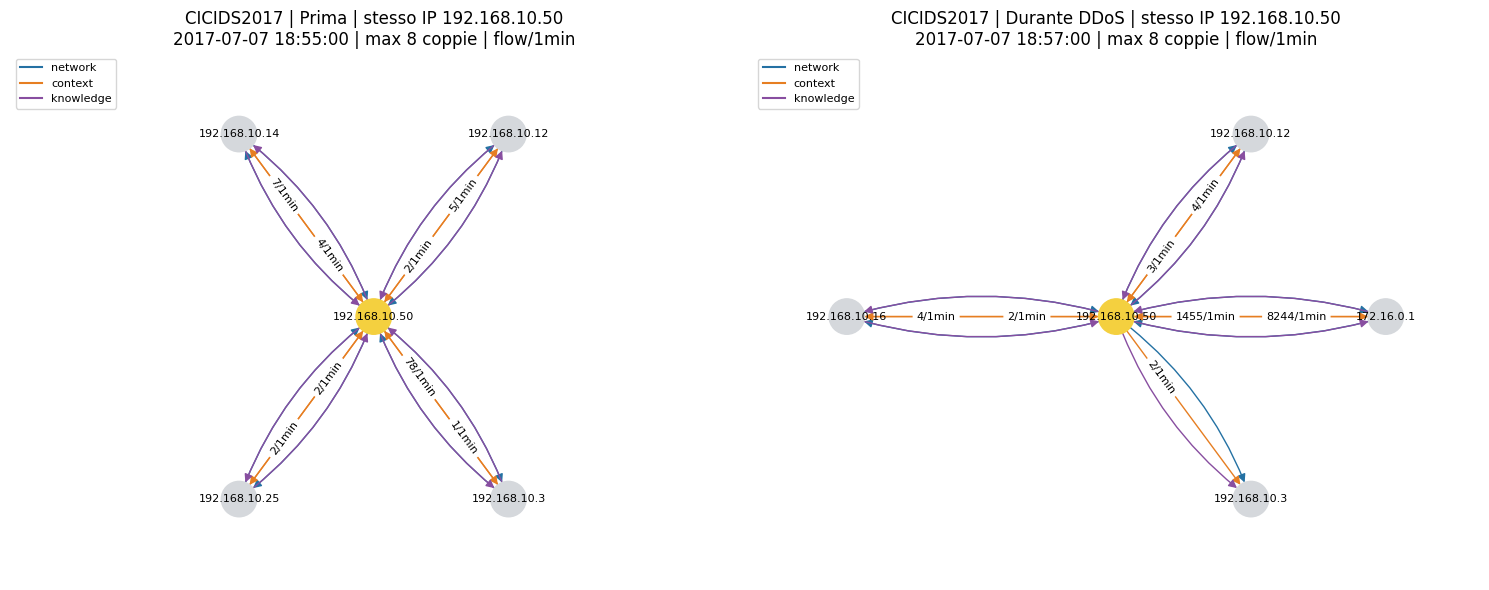

In [13]:
# 2. DIMENSIONI, CLASSI, FEATURE E STESSO HOST PRIMA/DURANTE L'ATTACCO
display(pd.DataFrame([{"dataset": name, "file": len(DATASETS[name]), "righe lette": frame.attrs["rows_read"],
    "scartate": frame.attrs["rows_read"]-len(frame), "flow validi": len(frame),
    "IP": len(set(frame["Source IP"]) | set(frame["Destination IP"])), "grafi/finestre": frame.window.nunique(),
    "benigni": int((frame.target==0).sum()), "attacchi": int(frame.target.sum()),
    "attacchi (%)": round(100*frame.target.mean(), 2)} for name, frame in datasets.items()]))
feature_summary = pd.DataFrame([
    ["network", "Source Port", "Porta del mittente", "edge_attr", "Si (tramite Φ)"],
    ["network", "Destination Port", "Porta del servizio destinatario", "edge_attr", "Si (tramite Φ)"],
    ["context", "Flow Duration", "Durata della comunicazione", "edge_attr", "Si (tramite Φ)"],
    ["context", "Flow IAT Mean", "Intervallo medio fra pacchetti del flow", "edge_attr", "Si (tramite Φ)"],
    ["knowledge", "Packet Length Std", "Variabilita delle dimensioni dei pacchetti", "edge_attr", "Si (tramite Φ)"],
    ["knowledge", "SYN Flag Count", "Pacchetti con flag TCP SYN", "edge_attr", "Si (tramite Φ)"],
    ["nodi", "community", "ID della comunita topologica locale", "x", "Si"],
    ["nodi", "in_degree", "Flow entranti nell'IP nella finestra", "x", "Si"],
    ["nodi", "out_degree", "Flow uscenti dall'IP nella finestra", "x", "Si"],
], columns=["famiglia", "feature", "significato", "dove si trova", "usata dal modello"])
display(feature_summary)

def same_host_scenarios(df):
    attacks = df[df["target"] == 1]
    ddos = attacks[attacks["attack_type"].str.contains("ddos", case=False, na=False)]
    if not ddos.empty:
        attacks = ddos
    for host in attacks["Destination IP"].value_counts().index:
        incoming = attacks[attacks["Destination IP"] == host]
        first_attack = incoming["window"].min()
        incident = df[(df["Source IP"] == host) | (df["Destination IP"] == host)]
        earlier = incident[incident["window"] < first_attack]
        benign_windows = earlier.groupby("window")["target"].sum()
        benign_windows = benign_windows[benign_windows == 0]
        if not benign_windows.empty:
            before = incident[incident["window"] == benign_windows.index.max()]
            peak = incoming.groupby("window").size().idxmax()
            during = incident[incident["window"] == peak]
            return host, before, during
    return None


for dataset_name, df in datasets.items():
    print(dataset_name)
    counts = df["attack_type"].value_counts().rename("flow").to_frame()
    counts["percentuale (%)"] = (100*counts["flow"]/len(df)).round(2)
    display(counts)
    scenario = same_host_scenarios(df)
    if scenario is None:
        print("Nessun host con traffico benigno precedente e attacco successivo nei dati selezionati.")
    else:
        host, before, during = scenario
        scenario_summary = pd.DataFrame([
            {"scenario": name, "IP osservato": host, "minuto": part["window"].iloc[0],
             "flow benigni": int((part["target"] == 0).sum()), "flow attacco": int(part["target"].sum())}
            for name, part in [("prima", before), ("durante attacco", during)]
        ])
        display(scenario_summary)
        shown_pairs = []
        for part in [before, during]:
            pairs = part.groupby(["Source IP", "Destination IP"]).size().sort_values(ascending=False)
            shown_pairs.append(pairs.head(MAX_GRAPH_PAIRS))
        union = nx.DiGraph()
        for pairs in shown_pairs:
            union.add_edges_from(pairs.index)
        peers = sorted(set(union.nodes) - {host})
        positions = {host: (0, 0)}
        positions.update({peer: (np.cos(2*np.pi*i/len(peers)), np.sin(2*np.pi*i/len(peers)))
                          for i, peer in enumerate(peers)})
        fig, axes = plt.subplots(1, 2, figsize=(15, 6))
        relation_colors = ["#2471a3", "#e67e22", "#884ea0"]
        for ax, title, part, pairs in zip(axes, ["Prima", "Durante DDoS" if during["attack_type"].str.contains("ddos", case=False, na=False).any() else "Durante attacco"], [before, during], shown_pairs):
            graph = nx.DiGraph()
            graph.add_edges_from(pairs.index)
            nx.draw_networkx_nodes(graph, positions, ax=ax, node_size=650,
                node_color=["#f4d03f" if node == host else "#d5d8dc" for node in graph.nodes])
            nx.draw_networkx_labels(graph, positions, ax=ax, font_size=8)
            for color, radius in zip(relation_colors, [-0.15, 0, 0.15]):
                nx.draw_networkx_edges(graph, positions, ax=ax, node_size=650, edge_color=color,
                    arrowsize=12, connectionstyle=f"arc3,rad={radius}")
            labels = {(u, v): f"{int(count)}/{WINDOW_MINUTES}min" for (u, v), count in pairs.items()}
            nx.draw_networkx_edge_labels(graph, positions, ax=ax, edge_labels=labels, font_size=8, label_pos=0.32)
            ax.legend(handles=[Line2D([0], [0], color=color, label=name)
                               for name, color in zip(SEMANTICS, relation_colors)], loc="upper left", fontsize=8)
            ax.set_title(f"{dataset_name} | {title} | stesso IP {host}\n{part['window'].iloc[0]} | max {MAX_GRAPH_PAIRS} coppie | flow/{WINDOW_MINUTES}min")
            ax.set(xlim=(-1.35, 1.35), ylim=(-1.25, 1.25))
            ax.axis("off")
        plt.tight_layout()
        plt.show()


In [ ]:
# 3. GRID SEARCH, EARLY STOPPING, CHECKPOINT E SOGLIA VALIDATION
class HeteroEdgeClassifier(nn.Module):
    def __init__(self, hidden_channels=64, out_channels=32, num_classes=2, dropout=0.2):
        super().__init__()

        self.conv1 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(-1, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn1_ip = nn.BatchNorm1d(hidden_channels)

        self.conv2 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(hidden_channels, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn2_ip = nn.BatchNorm1d(hidden_channels)

        self.lin_node = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels * 2),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_channels * 2, out_channels),
            nn.ReLU()
        )

        self.lin_edge = nn.Sequential(
            nn.Linear(out_channels * 2, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, num_classes)
        )

    def forward(self, data):
        x_dict = self.conv1(data.x_dict, data.edge_index_dict)
        x_dict['ip'] = (self.bn1_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn1_ip.running_mean, self.bn1_ip.running_var,
                                      self.bn1_ip.weight, self.bn1_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict = self.conv2(x_dict, data.edge_index_dict)
        x_dict['ip'] = (self.bn2_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn2_ip.running_mean, self.bn2_ip.running_var,
                                      self.bn2_ip.weight, self.bn2_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict['ip'] = self.lin_node(x_dict['ip'])
        return x_dict

    def edge_classify(self, z_src, z_dst):
        z_cat = torch.cat([z_src, z_dst], dim=-1)
        logits = self.lin_edge(z_cat)
        return logits



# =====================================================================
# [CASO 0 - PAPER] Funzione di valutazione degli archi Φ (eq. 4 del paper)
# Φ(u,v,k) = Σ_i α_i^k · Norm(x_i): un peso per ogni arco, passato alle GCNConv come edge_weight.
# Norm = log1p + min-max con minimo e massimo del TRAIN del fold; α >= 0 tramite softplus (init 0.5).
# Minimo e massimo sono salvati come buffer del modello: finiscono nel checkpoint e vengono
# ripristinati con load_state_dict, quindi il test usa sempre le statistiche del proprio fold.
# =====================================================================
PHI_STATS = None  # statistiche min-max del train del fold corrente (impostate nel ciclo principale)

def phi_values(edge_attr):
    return torch.log1p(edge_attr.abs())

def fit_phi_stats(train_graphs):
    stats = {}
    for relation in RELATIONS:
        values = torch.cat([phi_values(g[relation].edge_attr) for g in train_graphs])
        stats[relation[1]] = (values.min(dim=0).values, values.max(dim=0).values)
    return stats

class PaperEdgeClassifier(HeteroEdgeClassifier):
    def __init__(self, hidden_channels=64, out_channels=32, num_classes=2, dropout=0.2):
        super().__init__(hidden_channels=hidden_channels, out_channels=out_channels,
                         num_classes=num_classes, dropout=dropout)
        init = float(np.log(np.expm1(0.5)))   # softplus(init) = 0.5: all'inizio tutte le feature pesano uguale
        self.phi_alpha = nn.ParameterDict({r[1]: nn.Parameter(torch.full((2,), init)) for r in RELATIONS})
        for r in RELATIONS:
            self.register_buffer(f"phi_min_{r[1]}", torch.zeros(2))
            self.register_buffer(f"phi_max_{r[1]}", torch.ones(2))

    def set_phi_stats(self, stats):
        for name, (low, high) in stats.items():
            getattr(self, f"phi_min_{name}").copy_(low)
            getattr(self, f"phi_max_{name}").copy_(high)

    def edge_weights(self, data):
        weights = {}
        for relation in RELATIONS:
            name = relation[1]
            low, high = getattr(self, f"phi_min_{name}"), getattr(self, f"phi_max_{name}")
            norm = ((phi_values(data[relation].edge_attr) - low) / (high - low).clamp_min(1e-12)).clamp(0.0, 1.0)
            weights[relation] = (norm * F.softplus(self.phi_alpha[name])).sum(dim=-1)
        return weights

    def alphas(self):
        return {r[1]: F.softplus(self.phi_alpha[r[1]]).detach().cpu().tolist() for r in RELATIONS}

    def forward(self, data):
        edge_weight_dict = self.edge_weights(data)   # [PAPER] archi pesati da Φ
        x_dict = self.conv1(data.x_dict, data.edge_index_dict, edge_weight_dict=edge_weight_dict)
        x_dict['ip'] = (self.bn1_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn1_ip.running_mean, self.bn1_ip.running_var,
                                      self.bn1_ip.weight, self.bn1_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict = self.conv2(x_dict, data.edge_index_dict, edge_weight_dict=edge_weight_dict)
        x_dict['ip'] = (self.bn2_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn2_ip.running_mean, self.bn2_ip.running_var,
                                      self.bn2_ip.weight, self.bn2_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict['ip'] = self.lin_node(x_dict['ip'])
        return x_dict

def focal_loss(logits, targets):
    ce = F.cross_entropy(logits, targets, reduction="none")
    return (FOCAL_ALPHA * (1 - torch.exp(-ce)) ** FOCAL_GAMMA * ce).mean()

def graph_loss(model, graph):
    z = model(graph)["ip"]
    return sum(focal_loss(model.edge_classify(z[graph[r].edge_index[0]], z[graph[r].edge_index[1]]),
                          graph[r].edge_label) for r in RELATIONS)

@torch.no_grad()
def predict(model, items, device, batch_size=4):
    model.eval()
    rows = []
    for batch in DataLoader(items, batch_size=batch_size, shuffle=False, num_workers=LOADER_WORKERS):
        batch = batch.to(device)
        z = model(batch)["ip"]
        src, dst = batch[RELATIONS[0]].edge_index
        rows.append(pd.DataFrame({"flow_id": batch.flow_id.cpu().numpy(),
            "target": batch[RELATIONS[0]].edge_label.cpu().numpy(),
            "score": model.edge_classify(z[src], z[dst]).softmax(-1)[:, 1].cpu().numpy()}))
    return pd.concat(rows, ignore_index=True)

def choose_threshold(items):
    if items.target.nunique() != 2:
        raise ValueError("Servono benigni e attacchi per scegliere la soglia F1.")
    if not np.isfinite(items.score).all():
        raise ValueError("Score non finiti.")
    p, r, thresholds = precision_recall_curve(items.target, items.score)
    denominator = p[:-1] + r[:-1]
    f1 = np.divide(2*p[:-1]*r[:-1], denominator, out=np.zeros_like(denominator), where=denominator>0)
    return float(thresholds[np.flatnonzero(f1 == f1.max())[-1]])

def split_graphs(graphs, seed=None):
    if seed is None:
        seed = SPLIT_SEED
    if len(graphs)<3:
        raise ValueError("Servono almeno tre finestre per train, validation e test.")
    rest_size = max(2, int(np.ceil((HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)*len(graphs))))
    if rest_size>=len(graphs):
        raise ValueError("Le frazioni holdout lasciano troppo pochi grafi nel train")
    indices = np.arange(len(graphs))
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    classes, counts = np.unique(strata,return_counts=True)
    stratify = strata if min(counts)>=4 and min(rest_size,len(graphs)-rest_size)>=len(classes) else None
    train, rest = train_test_split(indices,test_size=rest_size,random_state=seed,stratify=stratify)
    ratio = HOLDOUT_TEST_FRACTION/(HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)
    test_size = min(len(rest)-1,max(1,int(np.ceil(ratio*len(rest)))))
    classes, counts = np.unique(strata[rest],return_counts=True)
    stratify = strata[rest] if min(counts)>=2 and min(test_size,len(rest)-test_size)>=len(classes) else None
    val, test = train_test_split(rest,test_size=test_size,random_state=seed,stratify=stratify)
    return [[graphs[i] for i in part] for part in [train,val,test]]

def new_model(params):
    # [CASO 0 - PAPER] modello con Φ; le statistiche min-max sono quelle del train del fold corrente.
    # Nel test (cella 4) vengono poi sovrascritte da load_state_dict con quelle salvate nel checkpoint.
    args = {k: params[k] for k in ["hidden_channels", "out_channels", "dropout"]}
    if not USA_PHI:
        return HeteroEdgeClassifier(**args)       # senza Φ: V1 di Marco
    model = PaperEdgeClassifier(**args)           # con Φ: caso 0 del paper
    if PHI_STATS is not None:
        model.set_phi_stats(PHI_STATS)
    return model

def save_checkpoint(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

def train_model(train_items, val_items, params, checkpoint_path, max_epochs, patience, min_delta):
    if max_epochs < 1 or (EARLY_STOPPING and (patience < 1 or min_delta < 0 or not np.isfinite(min_delta))):
        raise ValueError("Epoche/patience positive e min_delta non negativo.")
    seed_everything(SEED)
    model = new_model(params).to(DEVICE)
    # [COSTO] memoria GPU di picco e tempo per epoca
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    epoch_times = []
    optimizer = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_items, batch_size=params["batch_size"], shuffle=True,
                              generator=generator, num_workers=LOADER_WORKERS)
    val_loader = DataLoader(val_items, batch_size=params["batch_size"], shuffle=False, num_workers=LOADER_WORKERS)
    history, best_loss, significant_loss, stale = [], float("inf"), float("inf"), 0
    progress = tqdm(range(1, max_epochs+1), desc=Path(checkpoint_path).stem, unit="epoca", position=0, leave=True)
    for epoch in progress:
        t_epoch = time.perf_counter()  # [COSTO]
        model.train()
        train_sum, train_count = 0., 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            loss = graph_loss(model, batch)
            if not torch.isfinite(loss):
                raise RuntimeError("Loss train non finita.")
            loss.backward()
            optimizer.step()
            count = batch[RELATIONS[0]].num_edges
            train_sum += loss.item()*count
            train_count += count
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        epoch_times.append(time.perf_counter() - t_epoch)  # [COSTO] solo training, senza validation
        model.eval()
        val_sum, val_count = 0., 0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(DEVICE)
                count = batch[RELATIONS[0]].num_edges
                val_sum += graph_loss(model, batch).item()*count
                val_count += count
        train_loss, val_loss = train_sum/train_count, val_sum/val_count
        if not np.isfinite(val_loss):
            raise RuntimeError("Loss validation non finita.")
        history.append({"epoca": epoch, "train": train_loss, "validation": val_loss})
        if val_loss < best_loss:
            best_loss = val_loss
            save_checkpoint({"state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "params": params, "best_epoch": epoch, "validation_loss": val_loss, "seed": SEED}, checkpoint_path)
        if EARLY_STOPPING:
            if val_loss < significant_loss - min_delta:
                significant_loss, stale = val_loss, 0
            else:
                stale += 1
        progress.set_postfix(train=f"{train_loss:.5f}", validation=f"{val_loss:.5f}", attesa=stale if EARLY_STOPPING else "off")
        if EARLY_STOPPING and stale >= patience:
            break
    progress.close()
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model.load_state_dict(checkpoint["state_dict"])
    validation = predict(model, val_items, DEVICE, params["batch_size"])
    threshold = choose_threshold(validation)
    vp, vr, vf1, _ = precision_recall_fscore_support(validation.target, validation.score>=threshold,
                                                   average="binary", zero_division=0)
    checkpoint.update({"threshold": threshold, "history": history,
        "validation_F1": float(vf1), "validation_AP": float(average_precision_score(validation.target, validation.score)),
        "epochs_run": len(history), "stopped_early": len(history)<max_epochs, "early_stopping": EARLY_STOPPING,
        "focal_alpha": FOCAL_ALPHA, "focal_gamma": FOCAL_GAMMA,
        # [COSTO] parametri contati qui: i layer con -1 (GCNConv lazy) creano i pesi solo al primo passaggio dei dati
        "n_parametri": sum(p.numel() for p in model.parameters()),
        "secondi_per_epoca": float(np.mean(epoch_times)),
        "memoria_gpu_MB": float(torch.cuda.max_memory_allocated() / 2**20) if torch.cuda.is_available() else None})
    save_checkpoint(checkpoint, checkpoint_path)
    return checkpoint

def flow_counts(flows):
    return flows.groupby(["window", "Source IP", "Destination IP"]).size().rename("flow_count").reset_index()

def count_features(flows):
    result = flows[["flow_id", "window", "Source IP", "Destination IP", "target", "attack_type"]].merge(
        flow_counts(flows), on=["window", "Source IP", "Destination IP"], validate="many_to_one")
    result["source_out"] = result.groupby(["window", "Source IP"])["flow_id"].transform("size")
    result["destination_in"] = result.groupby(["window", "Destination IP"])["flow_id"].transform("size")
    return result

def fit_count_thresholds(train_flows):
    counts = flow_counts(train_flows).flow_count
    if counts.empty:
        raise ValueError("Nessuna coppia IP/minuto nel train.")
    return {f"P{q:g}": float(counts.quantile(q/100)) for q in COUNT_PERCENTILES}


def evaluation_splits(graphs, dataset_name):
    count = N_FOLDS.get(dataset_name, 1)
    if isinstance(count, bool) or not isinstance(count, int) or not 1 <= count <= len(graphs):
        raise ValueError(f"{dataset_name}: N_FOLDS deve essere 1 oppure un intero da 2 a {len(graphs)}")
    if len({g.window for g in graphs}) != len(graphs):
        raise ValueError("Ogni minuto deve corrispondere a un solo grafo prima dei fold")
    selected = FOLDS_TO_RUN.get(dataset_name)
    if selected is not None:
        if (not isinstance(selected, (list,tuple)) or not selected
            or any(isinstance(f,bool) or not isinstance(f,int) or not 1 <= f <= count for f in selected)
            or len(set(selected)) != len(selected)):
            raise ValueError(f"{dataset_name}: FOLDS_TO_RUN deve essere None o una lista senza duplicati fra 1 e {count}")
    if count == 1:
        return [(1, *split_graphs(graphs, SPLIT_SEED))]
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    counts = np.unique(strata, return_counts=True)[1]
    splitter = (StratifiedKFold(count, shuffle=True, random_state=SPLIT_SEED) if min(counts) >= count
                else KFold(count, shuffle=True, random_state=SPLIT_SEED))
    folds = []
    for fold, (remaining, test) in enumerate(splitter.split(np.arange(len(graphs)), strata), 1):
        if selected is not None and fold not in selected:
            continue
        if len(remaining) < 3:
            raise ValueError("Troppi pochi grafi per separare train e validation dentro ogni fold")
        labels = strata[remaining]
        classes, frequencies = np.unique(labels, return_counts=True)
        val_size = int(np.ceil(KFOLD_VAL_FRACTION*len(remaining)))
        stratify = labels if min(frequencies)>=2 and val_size>=len(classes) and len(remaining)-val_size>=len(classes) else None
        train, val = train_test_split(remaining, test_size=KFOLD_VAL_FRACTION, random_state=SPLIT_SEED, stratify=stratify)
        parts = [[graphs[i] for i in indices] for indices in [train,val,test]]
        for name, part in zip(["train","validation","test"],parts):
            labels = {int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()}
            if labels != {0,1}:
                raise ValueError(f"{dataset_name}, fold {fold}: {name} non contiene entrambe le classi; ridurre i fold o cambiare split")
        folds.append((fold,*parts))
    tested = [g.window for _,_,_,test in folds for g in test]
    assert len(tested) == len(set(tested)), "Finestre ripetute nei test esterni"
    if selected is None:
        assert set(tested) == {g.window for g in graphs}, "K-fold incompleta"
    return folds

experiments = {}
for dataset_name, df in datasets.items():
    graphs = [build_graph(part) for _, part in tqdm(df.groupby("window", sort=True), desc=f"Grafi {dataset_name}")]
    assert sum(g[RELATIONS[0]].num_edges for g in graphs) == len(df)
    n_folds = N_FOLDS.get(dataset_name,1)
    if not GRID_SEARCH and dataset_name not in MODEL_PARAMS:
        raise ValueError(f"Mancano MODEL_PARAMS per {dataset_name}")
    fold_splits = evaluation_splits(graphs,dataset_name)
    # [SEED] ogni seed rifà tutti i fold con gli stessi split; SEED (globale) viene letto da train_model
    seed_runs = [(s, *split) for s in SEEDS for split in fold_splits]
    for SEED, fold, train_graphs, val_graphs, test_graphs in seed_runs:
        seed_everything(SEED)
        folder = RUN_DIR/dataset_name/f"seed_{SEED}"
        if n_folds>1:
            folder = folder/f"fold_{fold:02d}"
        folder.mkdir(parents=True,exist_ok=True)
        experiment_key = f"{dataset_name}/seed_{SEED}" if n_folds==1 else f"{dataset_name}/seed_{SEED}/fold_{fold:02d}"
        print(f"{dataset_name} | seed {SEED} | fold {fold}/{n_folds}",flush=True)
        parts = [train_graphs, val_graphs, test_graphs]
        windows = [{g.window for g in part} for part in parts]
        ids = [{int(i) for g in part for i in g.flow_id.tolist()} for part in parts]
        assert all(windows[i].isdisjoint(windows[j]) and ids[i].isdisjoint(ids[j]) for i in range(3) for j in range(i))
        assert all(len({int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()}) == 2 for part in parts), "Ogni split deve contenere benigni e attacchi"
        split_table = pd.DataFrame([{"split": name, "grafi": len(part), "flow": len(flow_ids),
            "attacchi": sum(int(g[RELATIONS[0]].edge_label.sum()) for g in part)}
            for name, part, flow_ids in zip(["train", "validation", "test"], parts, ids)])
        print(dataset_name, "| 0 finestre e 0 flow_id condivisi; split di grafi interi, train/validation/test disgiunti")
        display(split_table)
        split_table.to_csv(folder/"split_summary.csv", index=False)
        pd.DataFrame([{"flow_id": i, "split": name} for name, flow_ids in zip(["train", "validation", "test"], ids)
                      for i in sorted(flow_ids)]).to_csv(folder/"split_flows.csv", index=False)
        PHI_STATS = fit_phi_stats(train_graphs)   # [CASO 0 - PAPER] min-max solo sul train di questo fold
        print("Min-max Φ (train, dopo log1p):", {k: [v.tolist() for v in pair] for k, pair in PHI_STATS.items()})
        grid_rows, champion, champion_path = [], None, None
        grid = (list(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else [MODEL_PARAMS[dataset_name]])
        for trial, params in enumerate(grid, 1):
            print(f"{dataset_name} | configurazione {trial}/{len(grid)}", flush=True)
            checkpoint_path = folder / "checkpoints" / f"trial_{trial:03d}.pt"
            start = time.perf_counter()
            checkpoint = train_model(train_graphs, val_graphs, params, checkpoint_path, MAX_EPOCHS, PATIENCE, MIN_DELTA)
            row = {"trial": trial, **params, **{k: checkpoint[k] for k in ["best_epoch", "epochs_run", "stopped_early", "validation_loss", "validation_F1", "validation_AP", "threshold"]},
                   "seconds": time.perf_counter()-start}
            grid_rows.append(row)
            pd.DataFrame(grid_rows).to_csv(folder/"grid_search.csv", index=False)
            rank = (checkpoint["validation_F1"], checkpoint["validation_AP"], -checkpoint["validation_loss"])
            if champion is None or rank > (champion["validation_F1"], champion["validation_AP"], -champion["validation_loss"]):
                champion, champion_path = checkpoint, checkpoint_path
                save_checkpoint(checkpoint, folder/"best_model.pt")
            print(f"{dataset_name} trial {trial}: F1 val {100*checkpoint['validation_F1']:.2f}% | epoca {checkpoint['best_epoch']}")
        display(pd.DataFrame(grid_rows).sort_values(["validation_F1", "validation_AP", "validation_loss"], ascending=[False,False,True]).head(5))
        print("Scelto:", champion_path.name, champion["params"], "| soglia validation:", champion["threshold"])
        experiments[experiment_key] = {"dataset": dataset_name, "seed": SEED, "fold": fold, "n_folds": n_folds, "folder": folder, "best": champion, "test_graphs": test_graphs,
            "train_ids": np.fromiter(ids[0], dtype=np.int64), "val_ids": np.fromiter(ids[1], dtype=np.int64), "test_ids": np.fromiter(ids[2], dtype=np.int64), "grid_rows": grid_rows}
        del train_graphs, val_graphs, parts
        gc.collect()
    del graphs,fold_splits
    gc.collect()


In [ ]:
# 4. TEST, BASELINE E CONFRONTO FINALE
def evaluation_metrics(target, score, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(target, predicted, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(target, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(target)) == 2
    return {"F1 (%)": 100*f1, "precision (%)": 100*precision, "recall (%)": 100*recall,
        "accuracy (%)": 100*accuracy_score(target, predicted),
        "AP (%)": 100*average_precision_score(target, score) if both else None,
        "ROC-AUC (%)": 100*roc_auc_score(target, score) if both else None,
        "balanced accuracy (%)": 100*balanced_accuracy_score(target, predicted),
        "MCC": float(matthews_corrcoef(target, predicted)),
        "veri negativi": int(tn), "falsi allarmi": int(fp), "attacchi mancati": int(fn), "veri positivi": int(tp),
        "FPR (%)": 100*fp/(fp+tn) if fp+tn else None}


def summarize_folds(comparisons, pair_rows, experiments, datasets, run_dir):
    metrics = ["F1 (%)","precision (%)","recall (%)","accuracy (%)","AP (%)","ROC-AUC (%)",
               "balanced accuracy (%)","MCC","FPR (%)","falsi allarmi","attacchi mancati"]
    for rows, filename in [(comparisons,"summary_test.csv"),(pair_rows,"summary_pairs.csv")]:
        frame = pd.DataFrame(rows)
        grouped = frame.groupby(["dataset","modello"])
        stats = grouped[metrics].agg(["mean","std"])
        stats.columns = [f"{metric} {stat}" for metric,stat in stats.columns]
        stats.insert(0,"fold eseguiti",grouped["fold"].nunique())
        stats.insert(0,"seed eseguiti",grouped["seed"].nunique())  # [SEED]
        stats.to_csv(run_dir/filename)
        print(filename,"| media e deviazione standard su tutti i run (seed x fold)")
        display(stats[["seed eseguiti","fold eseguiti","F1 (%) mean","F1 (%) std","recall (%) mean","falsi allarmi mean"]].round(2))
    # [SEED] per ogni seed la media sui fold; poi media e std FRA i seed (quanto cambia il risultato cambiando solo il seed)
    for rows, filename in [(comparisons,"summary_test"),(pair_rows,"summary_pairs")]:
        per_seed = pd.DataFrame(rows).groupby(["dataset","modello","seed"])[metrics].mean()
        per_seed.to_csv(run_dir/f"{filename}_per_seed.csv")
        between = per_seed.groupby(["dataset","modello"])[metrics].agg(["mean","std"])
        between.columns = [f"{metric} {stat}" for metric,stat in between.columns]
        between.to_csv(run_dir/f"{filename}_fra_seed.csv")
        print(f"{filename}_fra_seed.csv | media dei fold per seed, poi media e std fra i seed")
        display(between[["F1 (%) mean","F1 (%) std"]].round(2))
    coverage = []
    for name,df in datasets.items():
        runs = [e for e in experiments.values() if e["dataset"]==name and e["seed"]==SEEDS[0]]  # [SEED] copertura su un solo seed
        tested = [int(i) for e in runs for i in e["test_ids"]]
        assert len(tested)==len(set(tested)), "Flow valutati in piu test esterni"
        configured = runs[0]["n_folds"]
        if configured>1 and len(runs)==configured:
            assert set(tested)==set(df.flow_id), "La k-fold completa deve valutare tutti i flow"
        coverage.append({"dataset":name,"fold configurati":configured,"fold eseguiti":len(runs),
                         "flow test unici":len(tested),"flow dataset":len(df),"copertura (%)":100*len(tested)/len(df)})
    coverage = pd.DataFrame(coverage)
    coverage.to_csv(run_dir/"test_coverage.csv",index=False)
    display(coverage.round(2))

all_comparisons, all_pairs = [], []
for experiment in experiments.values():
    dataset_name = experiment["dataset"]
    fold, n_folds = experiment["fold"], experiment["n_folds"]
    SEED = experiment["seed"]  # [SEED]
    print(f"{dataset_name} | seed {SEED} | test fold {fold}/{n_folds}")
    folder, df = experiment["folder"], datasets[dataset_name]
    best = torch.load(folder/"best_model.pt", map_location="cpu", weights_only=True)
    model = new_model(best["params"])
    model.load_state_dict(best["state_dict"])
    model = model.to(DEVICE)
    # [COSTO] tempo per classificare tutto il test del fold
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_inf = time.perf_counter()
    predictions = predict(model, experiment["test_graphs"], DEVICE, best["params"]["batch_size"])
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    inference_seconds = time.perf_counter() - t_inf
    print(f"[COSTO] parametri {best['n_parametri']:,} | {best['secondi_per_epoca']:.1f} s/epoca | "
          f"memoria GPU {best['memoria_gpu_MB']} MB | inferenza test {inference_seconds:.1f} s")
    assert predictions.flow_id.is_unique and set(predictions.flow_id) == set(experiment["test_ids"])
    predictions["prediction"] = (predictions.score >= best["threshold"]).astype(int)
    predictions = predictions.merge(df[["flow_id", "window", "Source IP", "Destination IP", "attack_type"]],
                                     on="flow_id", validate="one_to_one")
    history = pd.DataFrame(best["history"]).set_index("epoca")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(history.index, history.train, marker="o", label="Train")
    ax.plot(history.index, history.validation, marker="s", label="Validation")
    ax.axvline(best["best_epoch"], color="gray", linestyle="--", label="Checkpoint scelto")
    ax.set(title=f"{dataset_name} | fold {fold}/{n_folds} | loss del modello scelto", xlabel="Epoca", ylabel="Focal loss media per flow")
    ax.legend(); fig.tight_layout(); fig.savefig(folder/"loss.png", dpi=PLOT_DPI); plt.show()

    train_flows = df[df.flow_id.isin(experiment["train_ids"])]
    test_flows = df[df.flow_id.isin(experiment["test_ids"])]
    train_counts = count_features(train_flows)
    count_predictions = count_features(test_flows).set_index("flow_id").loc[predictions.flow_id].reset_index()
    thresholds = fit_count_thresholds(train_flows)
    count_train_threshold = choose_threshold(train_counts[["target", "flow_count"]].rename(columns={"flow_count": "score"}))
    stump = DecisionTreeClassifier(max_depth=TREE_MAX_DEPTH, random_state=SEED).fit(train_counts[STUMP_FEATURES], train_counts.target)
    stump_rule = export_text(stump, feature_names=STUMP_FEATURES, decimals=2)
    print(dataset_name, "| percentili train:", thresholds, "| soglia F1 train:", count_train_threshold)
    print("Albero appreso sul train:\n" + stump_rule)
    print(f"Accuracy sempre benigno: {100*(predictions.target==0).mean():.2f}%")
    model_name = "Caso 0 (paper)" if USA_PHI else "Caso 0 senza Φ"
    specs = [(model_name, predictions.score.to_numpy(), predictions.prediction.to_numpy(), f"score >= {best['threshold']:.8g}")]
    
    for name, threshold in thresholds.items():
        count_predictions[name] = (count_predictions.flow_count > threshold).astype(int)
        specs.append((f"Dummy {name}", count_predictions.flow_count.to_numpy(), count_predictions[name].to_numpy(), f"flow > {threshold:g}"))
    count_predictions["Soglia_train"] = (count_predictions.flow_count >= count_train_threshold).astype(int)
    count_predictions["Albero"] = stump.predict(count_predictions[STUMP_FEATURES])
    specs.extend([
        ("Dummy soglia train", count_predictions.flow_count.to_numpy(), count_predictions.Soglia_train.to_numpy(), f"flow >= {count_train_threshold:g}"),
        (f"Albero profondita {TREE_MAX_DEPTH}", stump.predict_proba(count_predictions[STUMP_FEATURES])[:, 1], count_predictions.Albero.to_numpy(), "Regola train stampata sopra"),
    ])
    y = predictions.target.to_numpy()
    comparison_rows, unit_rows, reports = [], [], {}
    for name, scores, guessed, rule in specs:
        comparison_rows.append({"dataset": dataset_name, "seed": SEED, "fold": fold, "modello": name, "regola": rule,
                                **evaluation_metrics(y, scores, guessed)})
        pairs = predictions[["window", "Source IP", "Destination IP", "target"]].assign(score=scores, prediction=guessed)
        # Una coppia/minuto e positiva se contiene almeno un flow di attacco.
        pairs = pairs.groupby(["window", "Source IP", "Destination IP"]).agg(
            target=("target", "max"), score=("score", "max"), prediction=("prediction", "max"))
        unit_rows.append({"dataset":dataset_name,"seed":SEED,"fold":fold,"modello": name, "unita": "coppia IP/finestra", "totali": len(pairs),
                          "attacchi reali": int(pairs.target.sum()),
                          **evaluation_metrics(pairs.target, pairs.score, pairs.prediction)})
        reports[name] = classification_report(y, guessed, labels=[0, 1], target_names=["BENIGN", "ATTACK"],
                                               output_dict=True, zero_division=0)
    comparison = pd.DataFrame(comparison_rows).set_index("modello")
    columns = ["F1 (%)", "precision (%)", "recall (%)", "accuracy (%)", "AP (%)", "ROC-AUC (%)", "falsi allarmi", "attacchi mancati"]
    print(dataset_name, "| confronto sullo stesso test: una decisione per flow")
    display(comparison[columns].round(2))
    print("Controllo aggregato per coppia IP/finestra (target diverso dal singolo flow):")
    display(pd.DataFrame(unit_rows).set_index("modello")[["totali", "attacchi reali", "F1 (%)", "falsi allarmi", "attacchi mancati"]].round(2))
    attack_results = predictions.groupby("attack_type").apply(
        lambda part: pd.Series({"flow": len(part), "corretti (%)": 100*(part.target==part.prediction).mean()}))
    if USA_PHI:
        print("Coefficienti α della funzione Φ (dopo softplus):", {k: [round(a, 4) for a in v] for k, v in model.alphas().items()})
    print("Caso 0 (paper) per famiglia reale: corretti (%) = recall per attacco, specificita per BENIGN")
    display(attack_results.round(2))

    cols = min(3,len(specs)); rows = int(np.ceil(len(specs)/cols))
    fig, axes = plt.subplots(rows,cols,figsize=(5*cols,4*rows),squeeze=False)
    for ax, (name, scores, guessed, rule) in zip(axes.flat, specs):
        ConfusionMatrixDisplay(confusion_matrix(y, guessed, labels=[0, 1]), display_labels=["Benigno", "Attacco"]).plot(
            ax=ax, colorbar=False, values_format="d")
        ax.set(title=name, xlabel="Predizione", ylabel="Verita")
    for ax in list(axes.flat)[len(specs):]:
        ax.axis("off")
    fig.suptitle(f"{dataset_name} | fold {fold}/{n_folds} | confusion matrix sul test, conteggi dei flow")
    fig.tight_layout(); fig.savefig(folder/"confusion_matrices.png", dpi=PLOT_DPI); plt.show()
    fig, ax = plt.subplots(figsize=(8, 5))
    for index in [0, 1, len(specs)-1]:
        name, scores, guessed, rule = specs[index]
        precision, recall, _ = precision_recall_curve(y, scores)
        label = "Volume (tutte le soglie)" if index == 1 else name
        ax.plot(recall, precision, label=f"{label}: AP {average_precision_score(y, scores)*100:.2f}%")
    for name, scores, guessed, rule in specs:
        precision, recall, _, _ = precision_recall_fscore_support(y, guessed, average="binary", zero_division=0)
        ax.scatter([recall], [precision], s=35)
        ax.annotate(name, (recall, precision), xytext=(-6, -12), textcoords="offset points", ha="right", fontsize=7)
    ax.axhline(y.mean(), color="gray", linestyle="--", label="Riferimento casuale")
    ax.set(title=f"{dataset_name} | fold {fold}/{n_folds} | precision-recall sul test", xlabel="Recall attacchi", ylabel="Precision segnalazioni",
           xlim=(0, 1.02), ylim=(0, 1.02))
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(); fig.tight_layout(); fig.savefig(folder/"precision_recall.png", dpi=PLOT_DPI); plt.show()

    predictions.to_csv(folder/"predictions.csv", index=False)
    count_predictions.to_csv(folder/"count_baseline_predictions.csv", index=False)
    comparison.to_csv(folder/"comparison_test.csv")
    pd.DataFrame(unit_rows).to_csv(folder/"unit_comparison.csv", index=False)
    attack_results.to_csv(folder/"gcn_attack_families.csv")
    run = {"dataset": dataset_name, "files": [str(p) for p in DATASETS[dataset_name]], "rows": len(df),
        "windows": int(df.window.nunique()), "device": DEVICE_NAME, "cpu_threads": CPU_THREADS,
        "seed": SEED, "params": best["params"], "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "min_delta": MIN_DELTA,
        "best_epoch": best["best_epoch"], "epochs_run": best["epochs_run"], "threshold": best["threshold"],
        "selection": "checkpoint min validation loss; trial max validation F1, AP, then min loss; threshold max validation F1",
        "split": "random minute graphs 70/15/15; stratified by attack presence when possible",
        "test_flows": len(y), "test_attacks": int(y.sum()), "edge_features_used_by_model": USA_PHI, "phi_alphas": model.alphas() if USA_PHI else None,
        "count_baseline_thresholds": thresholds, "count_train_threshold": count_train_threshold, "stump_rule": stump_rule,
        "loss_history": best["history"], "comparison": comparison.reset_index().to_dict("records"),
        "classification_reports": reports, "accuracy_always_benign": float((y==0).mean()),
        "torch": str(torch.__version__), "pyg": str(torch_geometric.__version__)}
    run.update({"fold":fold,"n_folds":n_folds,
        "evaluation":"holdout" if n_folds==1 else "outer graph k-fold with inner validation",
        "grid_search":GRID_SEARCH,
        "cv_scope":"holdout" if n_folds==1 else ("grid selected on inner validation" if GRID_SEARCH else "fixed configuration; not a new cross-validated hyperparameter search"),
        "split":"disjoint minute graphs; shared by all compared models; external fold never used for checkpoint/threshold selection"})
    run.update({"grid_search":GRID_SEARCH,"early_stopping":EARLY_STOPPING,"split_seed":SPLIT_SEED,
        "holdout_test_fraction":HOLDOUT_TEST_FRACTION,"holdout_validation_fraction":HOLDOUT_VAL_FRACTION,
        "kfold_validation_fraction":KFOLD_VAL_FRACTION,"window_minutes":WINDOW_MINUTES,
        "focal_alpha":FOCAL_ALPHA,"focal_gamma":FOCAL_GAMMA,"count_percentiles":COUNT_PERCENTILES,
        "tree_max_depth":TREE_MAX_DEPTH,"loader_workers":LOADER_WORKERS,"gpu_requested":USE_GPU})
    run.update({"costo": {"n_parametri": best["n_parametri"], "secondi_per_epoca": best["secondi_per_epoca"],
                          "epoche": best["epochs_run"], "memoria_gpu_MB": best["memoria_gpu_MB"],
                          "inferenza_test_secondi": inference_seconds,
                          "ms_per_grafo_test": 1000 * inference_seconds / len(experiment["test_graphs"]),
                          "dispositivo": DEVICE_NAME}})
    (folder/"run.json").write_text(json.dumps(run, indent=2), encoding="utf-8")
    all_comparisons.extend(comparison_rows)
    all_pairs.extend(unit_rows)
    del model, train_counts, count_predictions
    gc.collect()
pd.DataFrame(all_comparisons).to_csv(RUN_DIR/"comparison_all_datasets.csv", index=False)
print("Esperimento completato. Risultati e checkpoint:", RUN_DIR)

summarize_folds(all_comparisons,all_pairs,experiments,datasets,RUN_DIR)


In [ ]:
import zipfile
from pathlib import Path
from IPython.display import FileLink

sorgente = Path("data/output_caso0_paper")
zip_path = Path("/kaggle/working/risultati_caso0.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorgente.rglob("*"):
        if f.is_file() and f.suffix != ".pt":   # niente checkpoint: pesano e non servono
            z.write(f, f.relative_to(sorgente))
print(f"{zip_path.stat().st_size/1e6:.1f} MB")
FileLink("risultati_caso0.zip")
